# 1、加载数据

In [6]:
import pandas as pd

df = pd.read_csv('top250_movie.csv',sep='#',encoding='utf8')
# df.head()
df.sample(5)

,movie_num,movie_name,movie_year,movie_country,movie_type,movie_director,movie_assess,movie_score,movie_url,movie_intro
15,16,大话西游之大圣娶亲,1995,香港 中国大陆,喜剧 爱情 奇幻 古装,刘镇伟 Jeffrey Lau,755195,9.2,https://movie.douban.com/subject/1292213/,一生所爱。
88,89,阿凡达,2009,美国 英国,动作 战争 科幻 冒险,詹姆斯·卡梅隆 James Cameron,724448,8.7,https://movie.douban.com/subject/1652587/,绝对意义上的美轮美奂。
200,201,一次别离,2011,伊朗 法国,剧情 家庭,阿斯哈·法哈蒂 Asghar Farhadi,159938,8.7,https://movie.douban.com/subject/5964718/,只有有信仰的人才能说出事实真相。
207,208,源代码,2011,美国 加拿大,科幻 悬疑 惊悚,邓肯·琼斯 Duncan Jones,494720,8.4,https://movie.douban.com/subject/3075287/,邓肯·琼斯继《月球》之后再度奉献出一部精彩绝伦的科幻佳作。
0,1,肖申克的救赎,1994,美国,犯罪 剧情,弗兰克·德拉邦特 Frank Darabont,1371845,9.6,https://movie.douban.com/subject/1292052/,希望让人自由。


# 2、查看数据基本信息

In [7]:
# 查看数据基本信息，查看各字段是否有缺失值
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 250 entries, 0 to 249
Data columns (total 10 columns):
movie_num         250 non-null int64
movie_name        250 non-null object
movie_year        250 non-null object
movie_country     250 non-null object
movie_type        250 non-null object
movie_director    250 non-null object
movie_assess      250 non-null int64
movie_score       250 non-null float64
movie_url         250 non-null object
movie_intro       250 non-null object
dtypes: float64(1), int64(2), object(7)
memory usage: 19.6+ KB


# 3、重复值检查

In [8]:
df.duplicated().value_counts()
#检查是否有重名电影
len(df.movie_name.unique()) # 值小于df.movie_name列的总行数，那么表示存在重复的值

250

# 4、国家或者地区上榜数的排名情况

In [9]:
# 对于 country 列，有些电影由多个国家或地区联合制作
country =df['movie_country'].str.split(' ').apply(pd.Series) # 按照空格分割成列表，并转换成Dataframe的列d
print(country)

        0     1    2    3    4    5
0      美国   NaN  NaN  NaN  NaN  NaN
1    中国大陆    香港  NaN  NaN  NaN  NaN
2      法国   NaN  NaN  NaN  NaN  NaN
3      美国   NaN  NaN  NaN  NaN  NaN
4     意大利   NaN  NaN  NaN  NaN  NaN
5      美国   NaN  NaN  NaN  NaN  NaN
6      日本   NaN  NaN  NaN  NaN  NaN
7      美国   NaN  NaN  NaN  NaN  NaN
8      美国    英国  NaN  NaN  NaN  NaN
9      美国    英国  NaN  NaN  NaN  NaN
10     美国   NaN  NaN  NaN  NaN  NaN
11     印度   NaN  NaN  NaN  NaN  NaN
12    意大利   NaN  NaN  NaN  NaN  NaN
13     法国    瑞士   德国  NaN  NaN  NaN
14     美国   NaN  NaN  NaN  NaN  NaN
15     香港  中国大陆  NaN  NaN  NaN  NaN
16     美国    英国  加拿大   冰岛  NaN  NaN
17     日本   NaN  NaN  NaN  NaN  NaN
18     美国   NaN  NaN  NaN  NaN  NaN
19     韩国   NaN  NaN  NaN  NaN  NaN
20     香港   NaN  NaN  NaN  NaN  NaN
21     美国   NaN  NaN  NaN  NaN  NaN
22     美国   NaN  NaN  NaN  NaN  NaN
23     美国   NaN  NaN  NaN  NaN  NaN
24     法国   NaN  NaN  NaN  NaN  NaN
25     美国   NaN  NaN  NaN  NaN  NaN
26     美国    英国  NaN  NaN  N

In [10]:
# 统计每个区域里相同国家的总数,将空值 NaN 替换为“0”
# pd.value_counts是pandas库中的一个函数，用于统计Series中各个元素出现的次数。
# 由于country DataFrame的每一列都包含了一些国家或地区的名称，
# apply函数将pd.value_counts应用到这些列上，分别计算每个国家或地区名称的出现次数。
all_country = country.apply(pd.value_counts).fillna('0').astype(int)
# all_country = country.apply(pd.value_counts).fillna('0')
print(all_country)
print("="*50)
all_country.columns = ['area1','area2','area3','area4','area5','area6']
# all_country['area1'] = all_country['area1'].astype(int)
# all_country['area2'] = all_country['area2'].astype(int)
# all_country['area3'] = all_country['area3'].astype(int)
# all_country['area4'] = all_country['area4'].astype(int)
# all_country['area5'] = all_country['area5'].astype(int)
# all_country['area6'] = all_country['area6'].astype(int)
# 计算每个国家参与制作电影总数排名情况
all_country['all_counts'] = all_country['area1']+all_country['area2']+all_country['area3']+ \
all_country['area4']+all_country['area5']+all_country['area6']


#按照'all_counts'列的值进行降序排序
all_country = all_country.sort_values(['all_counts'],ascending=False)
all_country.head(5)
#list(all_country.index)

        0   1  2  3  4  5
中国大陆   14   4  1  0  0  0
丹麦      1   0  0  0  0  0
伊朗      2   0  0  0  0  0
冰岛      0   0  0  1  0  0
加拿大     0   5  1  1  0  0
南非      0   1  1  0  0  0
印度      4   0  0  0  0  0
台湾      4   2  0  0  0  0
奥地利     0   1  0  0  0  0
巴西      1   0  1  0  0  0
希腊      0   1  0  0  0  0
德国      5  11  2  0  0  1
意大利     8   1  2  0  0  0
捷克      0   0  1  0  0  0
新西兰     1   2  0  0  0  0
日本     31   2  0  0  0  0
法国      9   9  1  1  0  0
波兰      0   0  0  1  0  0
泰国      1   0  0  0  0  0
澳大利亚    2   5  0  0  0  0
爱尔兰     1   0  0  0  0  0
瑞典      1   1  0  0  0  0
瑞士      0   3  1  0  0  0
美国    122  14  2  5  1  0
英国     14  15  4  0  0  0
荷兰      0   0  0  0  1  0
西德      0   0  1  0  0  0
西班牙     1   2  2  0  0  0
阿根廷     1   0  0  0  0  0
阿联酋     0   0  0  0  1  0
韩国      8   0  1  0  0  0
香港     19   8  0  0  0  0


,area1,area2,area3,area4,area5,area6,all_counts
美国,122,14,2,5,1,0,144
日本,31,2,0,0,0,0,33
英国,14,15,4,0,0,0,33
香港,19,8,0,0,0,0,27
法国,9,9,1,1,0,0,20


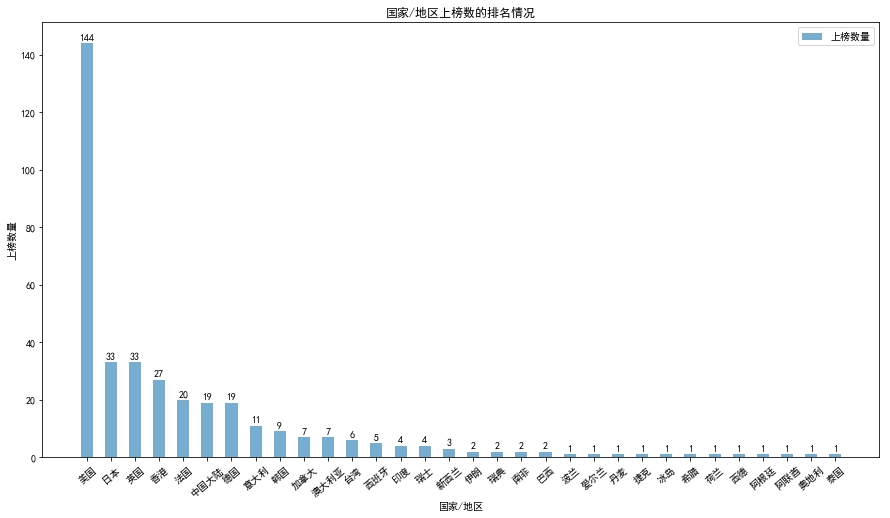

In [11]:
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['SimHei']

# 创建画布
fig = plt.figure(figsize=(15, 8))

# 添加柱状图数值
# for循环遍历索引和值，zip函数将all_country['all_counts']与其的值配对。
for x, y in zip(range(len(all_country['all_counts'])),all_country['all_counts']):
    # 在每个条形图的上方添加文本，设置水平对齐方式为居中
    plt.text(x, y+1, str(y), ha='center') 


plt.title("国家/地区上榜数的排名情况")
# 绘制条形图
plt.bar(all_country.index, all_country['all_counts'], width=0.5, alpha=0.6, lw=2, label='上榜数量')
plt.xticks( rotation=40)
plt.xlabel("国家/地区")
plt.ylabel("上榜数量")
plt.legend()
plt.show()

# 5、上榜电影类型排名 

In [12]:
all_type = df['movie_type'].str.split(' ').apply(pd.Series)
all_type = all_type.apply(pd.value_counts).fillna('0').astype(int)
all_type.columns = ['tpye1','type2','type3','type4','type5']
# all_type['tpye1'] = all_type['tpye1'].astype(int)
# all_type['type2'] = all_type['type2'].astype(int)
# all_type['type3'] = all_type['type3'].astype(int)
# all_type['type4'] = all_type['type4'].astype(int)
# all_type['type5'] = all_type['type5'].astype(int)
all_type.head(10)

all_type['all_counts'] = all_type['tpye1']+all_type['type2']+all_type['type3']+all_type['type4']+all_type['type5']

all_type = all_type.sort_values(['all_counts'],ascending=False)
all_type.head(10)

,tpye1,type2,type3,type4,type5,all_counts
剧情,162,22,5,0,0,189
爱情,3,39,18,0,0,60
喜剧,24,24,0,0,0,48
冒险,6,5,20,12,2,45
犯罪,12,23,7,3,0,45
奇幻,1,15,18,3,0,37
惊悚,0,7,15,11,2,35
动画,14,12,7,2,0,35
动作,17,12,3,0,0,32
悬疑,2,15,13,1,0,31


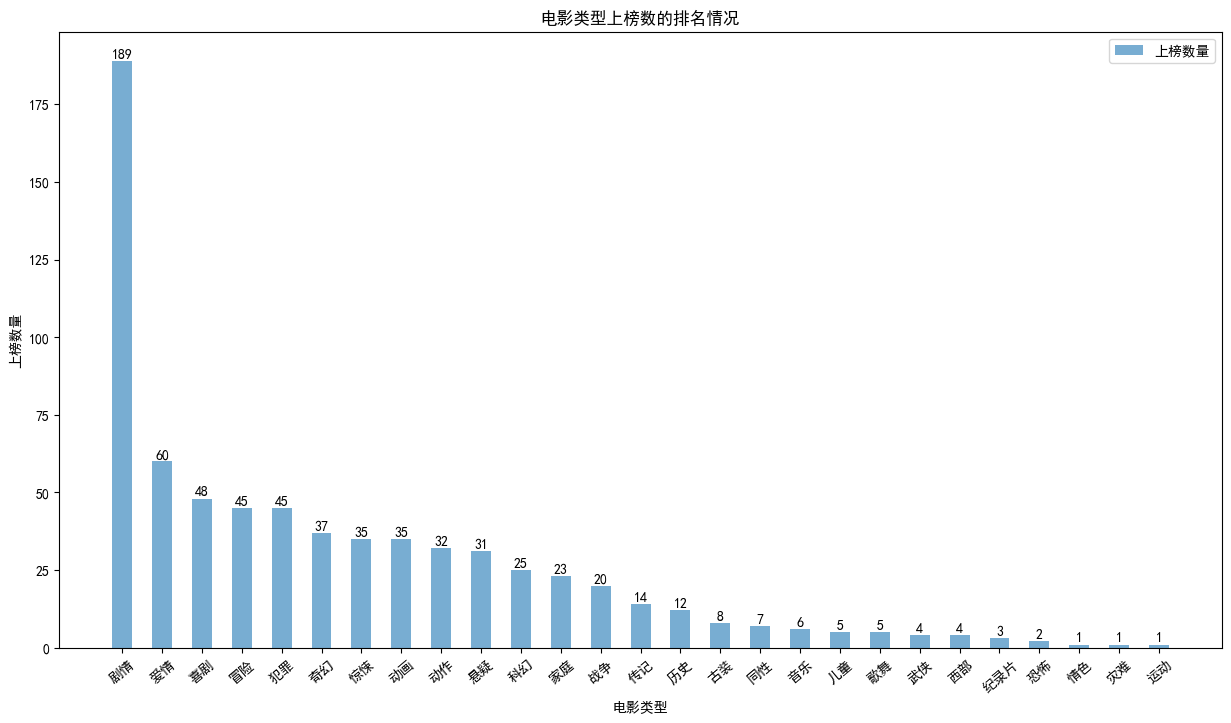

In [9]:
# 创建画布
fig = plt.figure(figsize=(15, 8))

# 添加柱状图数值
for x, y in zip(range(len(all_type['all_counts'])),all_type['all_counts']):
    plt.text(x, y+1, str(y), ha='center') 


plt.title("电影类型上榜数的排名情况")
plt.bar(all_type.index, all_type['all_counts'], width=0.5, alpha=0.6, lw=2, label='上榜数量')
plt.xticks( rotation=40)
plt.xlabel("电影类型")
plt.ylabel("上榜数量")
plt.legend()
plt.show()

# 6、上榜次数最多的导演

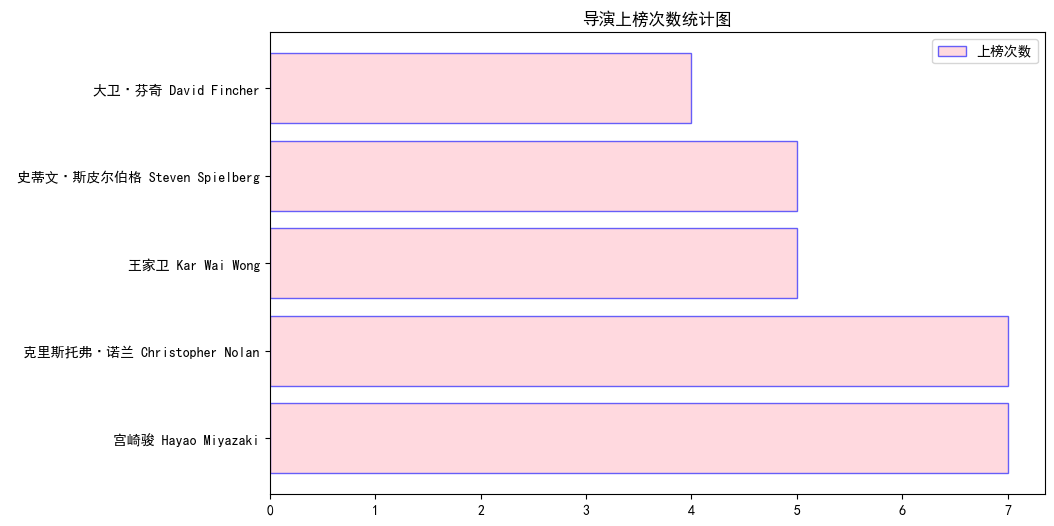

In [19]:
# value_counts()返回一个Series 序列
# 每个导演名称出现的次数，并返回一个Series对象，其中索引是唯一的导演名称，值是对应的计数。
# 并获取前5名导演
director = df['movie_director'].value_counts()[0:5]

# 创建画布
fig = plt.figure(figsize=(10, 6))

# 绘制图形
plt.title('导演上榜次数统计图')
# 绘制水平条形图
plt.barh(director.index, director.values, alpha=0.6, facecolor = 'pink', edgecolor = 'blue', label='上榜次数')
plt.legend()
plt.show()

# 7、评分和排名的关系

-0.7171361414557139

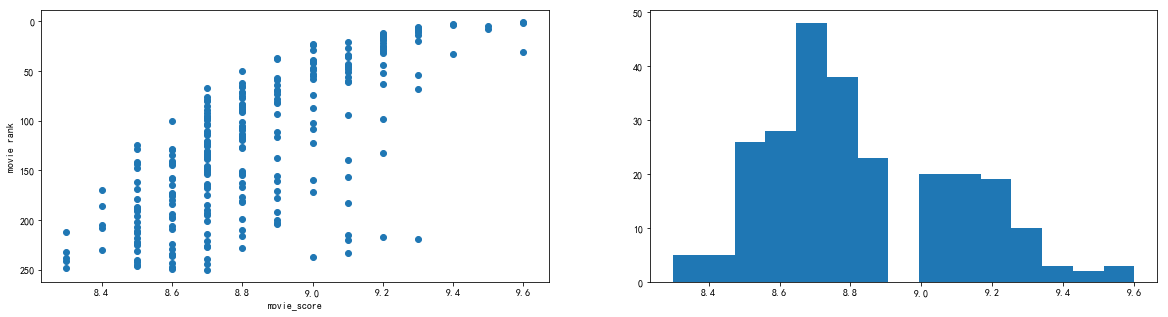

In [13]:
plt.figure(figsize=(20,5))
plt.subplot(1,2,1)
plt.scatter(df['movie_score'],df['movie_num'])
plt.xlabel('movie_score')
plt.ylabel('movie rank')
#修改y轴为倒序
plt.gca().invert_yaxis()

#集中趋势的直方图
plt.subplot(1,2,2)
plt.hist(df['movie_score'],bins=15)

#电影排名和评分的相关性检测，计算皮尔逊相关系数。
df['movie_score'].corr(df['movie_num'])

#out[35]:-0.69237508495035771

# 评分大多是集中在 8.3 - 9.2 之间，随评分的升高，豆瓣Top250排名名次也提前,Pearson相关系数为-0.6923，为强相关性

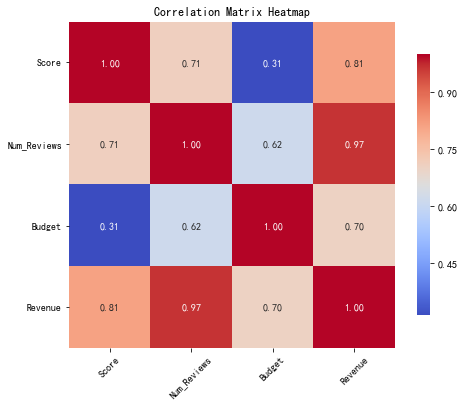

In [14]:
# 相关性矩阵
# 参考资料1：https://www.jb51.net/article/244645.htm
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# 创建一个示例DataFrame
data = {
    'Score': [85, 90, 78, 95, 88],
    'Num_Reviews': [120, 300, 200, 500, 150],
    'Budget': [30000000, 80000000, 55000000, 60000000, 40000000],
    'Revenue': [50000000, 150000000, 70000000, 200000000, 80000000]
}
df = pd.DataFrame(data)

# 计算相关性矩阵
corr_matrix = df.corr()

# 使用 seaborn 的 heatmap 函数绘制相关性矩阵
plt.figure(figsize=(8, 6))  # 设置图形大小
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap='coolwarm', 
            square=True, cbar_kws={"shrink": .8})

# 设置图表标题
plt.title('Correlation Matrix Heatmap')

# 优化x轴和y轴标签的显示
plt.xticks(rotation=45)
plt.yticks(rotation=0)

# 显示图表
plt.show()